# Student Performance Analysis
## Project Assignment 02
**Team:** #brokecode  
**Members:** Arnav Chawla, Patrick, Updesh Sachdeva  
**Analysis date:** October 19, 2026

We investigate how study time, absences, school support, and home internet access
relate to final Portuguese-language grades. These are observational comparisons,
not estimates of the causal effect of a policy or study habit.

Source: [UCI Student Performance](https://archive.ics.uci.edu/dataset/320/student+performance).
Citation: Cortez, P. (2008). Student Performance [Dataset]. UCI Machine Learning
Repository. https://doi.org/10.24432/C5TG7T. License: CC BY 4.0.

The dataset covers two Portuguese secondary schools and combines school reports
with questionnaires. It is historical and is not representative of all students.
We use only `student-por.csv`; we do not merge the overlapping subject files.

### Running this notebook
Install requirements.txt, run `python src/download_data.py` from the project root,
then open this notebook in Jupyter and select **Restart Kernel and Run All**.
Code resolves paths from either the repository root or notebooks folder.
No raw student rows are embedded in the saved outputs; outputs are aggregate summaries.


## Questions and analysis plan
1. Is higher study-time category associated with higher final grade? Expected direction: positive.
2. Are absences associated with lower final grade? Expected direction: negative.
3. Do mean grades differ between students receiving school support and those not receiving it?
4. Do mean grades differ by home internet access?

For questions 1 and 2 we use two-sided Spearman rank correlations (null: zero rank association).
For questions 3 and 4 we use two-sided Welch tests (null: equal population mean grades).
The four exploratory p-values receive a Holm adjustment, with an adjusted threshold of 0.05.
We report association sizes and mean differences as well as p-values. These calculations assume
independent observations, an approximation because students share schools/classes. Inference
is exploratory; we do not claim representative sampling or school-cluster-adjusted uncertainty.


In [1]:
from pathlib import Path
import sys
import hashlib
import json
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/analysis.py').exists())
sys.path.insert(0, str(ROOT / 'src'))
from analysis import load_students, group_summary, holm_adjust
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
(ROOT / 'figures').mkdir(exist_ok=True)
(ROOT / 'reports').mkdir(exist_ok=True)
def finish_plot(name):
    plt.tight_layout()
    plt.savefig(ROOT / 'figures' / name, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()

df = load_students()
print('Rows and columns:', df.shape)
print('CSV SHA256:', hashlib.sha256((ROOT/'data/student-por.csv').read_bytes()).hexdigest())
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__, '| seaborn:', sns.__version__)

Rows and columns: (649, 33)
CSV SHA256: a7594a11d7771c0efe1a740824e0e833da9c4cad07c39a9766a874575563fb3f
Python: 3.12.14 | pandas: 3.0.6 | seaborn: 0.13.2


## Data dictionary and checks
| Variable | Meaning | Treatment |
|---|---|---|
| G3 | Final grade, 0–20 | Main numeric outcome; retain zero grades |
| studytime | 1: <2; 2: 2–5; 3: 5–10; 4: >10 weekly hours | Ordered categories, not exact hours |
| absences | Number of school absences | Nonnegative count |
| schoolsup | Extra school educational support, yes/no | Separate from family support |
| internet | Home internet access, yes/no | Group comparison |
| school | GP or MS | Context and stratified checks |
| G1 and G2 | Earlier grading periods | Retained in source, excluded from primary questions |

We preserve all records unless there is evidence of a recording error. A zero grade is
a permitted value, not automatically missing. Matching rows alone would not prove the
same student was entered twice because the file has no unique student identifier.


In [2]:
checks = pd.DataFrame({
    'Check': ['Rows', 'Columns', 'Missing cells', 'Exact duplicate rows', 'Zero final grades'],
    'Result': [len(df), df.shape[1], int(df.isna().sum().sum()), int(df.duplicated().sum()), int(df.G3.eq(0).sum())]
})
display(checks)
display(df.dtypes.value_counts().rename('Column count').to_frame())
display(df[['age','studytime','absences','G1','G2','G3']].describe().round(2))
assert df.shape == (649,33), 'Unexpected source version: inspect before continuing'
assert df[['G1','G2','G3']].apply(lambda s: s.between(0,20).all()).all()
assert df.school.isin(['GP','MS']).all()
analysis = df.copy()
study_labels = {1:'<2 hours',2:'2–5 hours',3:'5–10 hours',4:'>10 hours'}
analysis['study_group'] = pd.Categorical(analysis.studytime.map(study_labels), categories=list(study_labels.values()), ordered=True)
print('Original records preserved. No imputation or outlier removal applied.')

Original records preserved. No imputation or outlier removal applied.


,Check,Result
0,Rows,649
1,Columns,33
2,Missing cells,0
3,Exact duplicate rows,0
4,Zero final grades,15


,Column count
str,17
int64,16


,age,studytime,absences,G1,G2,G3
count,649.00,649.00,649.00,649.00,649.00,649.00
mean,16.74,1.93,3.66,11.40,11.57,11.91
std,1.22,0.83,4.64,2.75,2.91,3.23
min,15.00,1.00,0.00,0.00,0.00,0.00
25%,16.00,1.00,0.00,10.00,10.00,10.00
50%,17.00,2.00,2.00,11.00,11.00,12.00
75%,18.00,2.00,6.00,13.00,13.00,14.00
max,22.00,4.00,32.00,19.00,19.00,19.00


## Final grade distribution
The histogram uses one bin per grade point. This establishes the outcome distribution
before interpreting comparisons between groups.

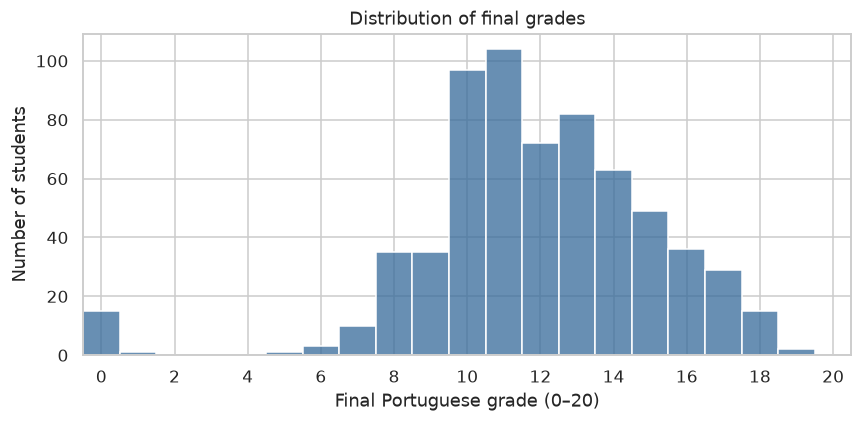

Mean final grade: **11.91/20**; median: **12/20**. There are **15** zero grades, which remain in the primary analysis.

In [3]:
plt.figure(figsize=(8,4))
sns.histplot(data=analysis, x='G3', bins=np.arange(-0.5,21.5,1), color='#356A9A')
plt.xticks(range(0,21,2)); plt.xlim(-0.5,20.5)
plt.xlabel('Final Portuguese grade (0–20)'); plt.ylabel('Number of students')
plt.title('Distribution of final grades')
finish_plot('01_final_grades.png')
display(Markdown(f"Mean final grade: **{df.G3.mean():.2f}/20**; median: **{df.G3.median():.0f}/20**. There are **{df.G3.eq(0).sum()}** zero grades, which remain in the primary analysis."))

## Study time and grades
Box plots show the median and spread within each ordered study-time category.
The summary table includes group sizes so that a small group is not mistaken for
equally strong evidence. The numeric codes 1–4 are not hour measurements.

,count,mean,median,std
study_group,,,,
<2 hours,212,10.844,11.0,3.219
2–5 hours,305,12.092,12.0,3.243
5–10 hours,97,13.227,13.0,2.502
>10 hours,35,13.057,13.0,3.038


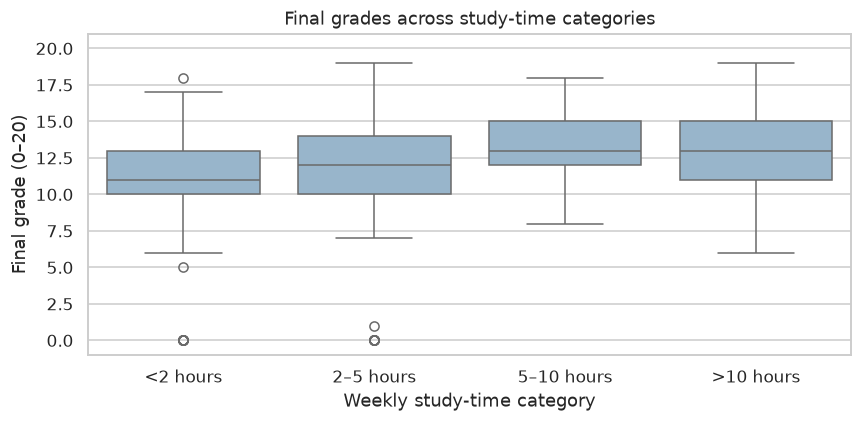

The observed Spearman correlation is **0.275**. This measures an ordered association; it does not show how many grade points an extra hour of studying would cause.

In [4]:
display(group_summary(analysis, 'study_group'))
plt.figure(figsize=(8,4))
sns.boxplot(data=analysis, x='study_group', y='G3', color='#90B6D3')
plt.ylim(-1,21); plt.xlabel('Weekly study-time category'); plt.ylabel('Final grade (0–20)')
plt.title('Final grades across study-time categories')
finish_plot('02_study_time.png')
rho_study, p_study = stats.spearmanr(df.studytime, df.G3)
display(Markdown(f"The observed Spearman correlation is **{rho_study:.3f}**. This measures an ordered association; it does not show how many grade points an extra hour of studying would cause."))

## Absences and grades
The scatter plot uses small, reproducible jitter to expose overlapping integer values.
Jitter changes display coordinates only; all calculations use the original values.
We retain zero grades, then repeat the correlation without them as a labeled sensitivity check.

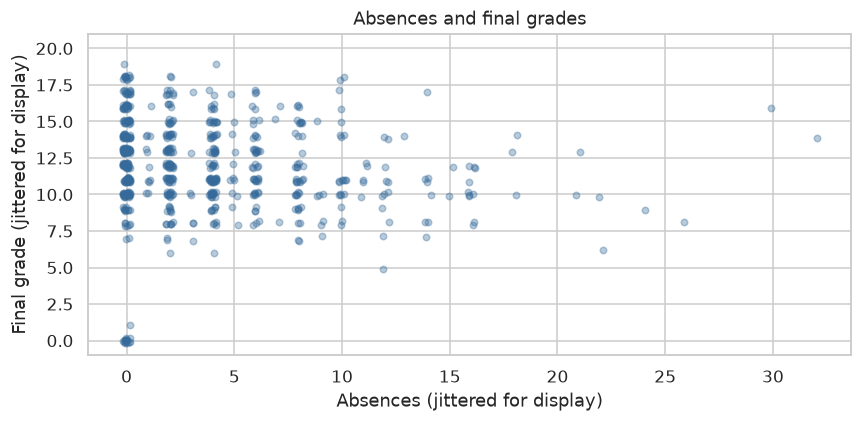

,Analysis,n,Spearman rho
0,All students (primary),649,-0.159
1,G3 > 0 only (sensitivity),634,-0.214


The sensitivity analysis changes the included population. It is not a replacement chosen to obtain a stronger result, and zero-grade records are not classified as errors.

In [5]:
rng = np.random.default_rng(122)
plt.figure(figsize=(8,4))
plt.scatter(df.absences+rng.uniform(-0.18,0.18,len(df)), df.G3+rng.uniform(-0.18,0.18,len(df)), alpha=.35, s=18, color='#356A9A')
plt.xlabel('Absences (jittered for display)'); plt.ylabel('Final grade (jittered for display)')
plt.ylim(-1,21); plt.title('Absences and final grades')
finish_plot('03_absences.png')
rho_abs, p_abs = stats.spearmanr(df.absences, df.G3)
nonzero = df.loc[df.G3 > 0]
rho_nonzero, _ = stats.spearmanr(nonzero.absences, nonzero.G3)
display(pd.DataFrame({'Analysis':['All students (primary)','G3 > 0 only (sensitivity)'], 'n':[len(df),len(nonzero)], 'Spearman rho':[rho_abs,rho_nonzero]}).round(3))
display(Markdown('The sensitivity analysis changes the included population. It is not a replacement chosen to obtain a stronger result, and zero-grade records are not classified as errors.'))

## Educational support and internet access
School support may be assigned to students already experiencing difficulty.
A lower average among supported students would not demonstrate that support is harmful.
Internet access can also reflect family resources or other unmeasured differences.

schoolsup
internet


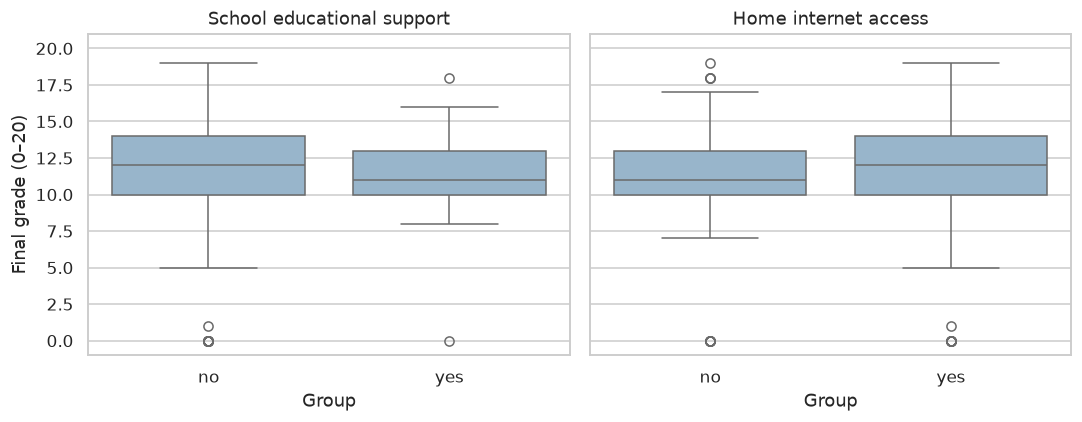

,count,mean,median,std
schoolsup,,,,
no,581,11.979,12.0,3.316
yes,68,11.279,11.0,2.304


,count,mean,median,std
internet,,,,
no,151,11.026,11.0,3.447
yes,498,12.173,12.0,3.117


In [6]:
fig, axes = plt.subplots(1,2,figsize=(10,4),sharey=True)
for ax, column, title in zip(axes,['schoolsup','internet'],['School educational support','Home internet access']):
    sns.boxplot(data=df,x=column,y='G3',order=['no','yes'],color='#90B6D3',ax=ax)
    ax.set(title=title,xlabel='Group',ylabel='Final grade (0–20)',ylim=(-1,21))
finish_plot('04_support_and_internet.png')
for column in ['schoolsup','internet']:
    print(column)
    display(group_summary(df,column))

## Rank associations among selected variables
This heatmap uses Spearman correlations. Background ordinal variables are interpreted
as ordered categories. Earlier grades are omitted so they do not dominate the research
questions about habits and circumstances.

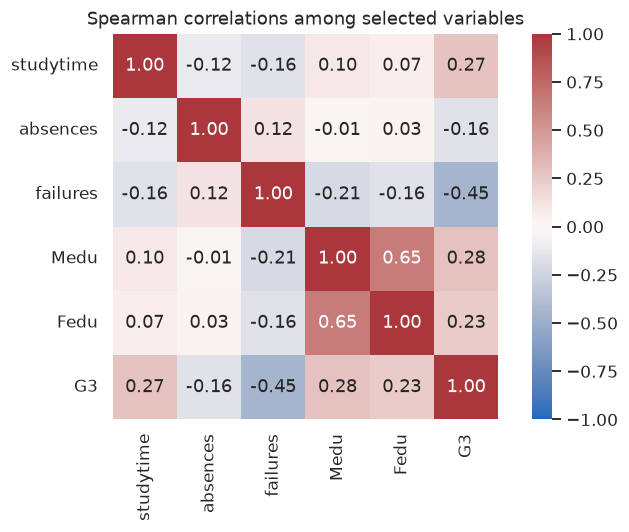

In [7]:
plt.figure(figsize=(7,5))
columns = ['studytime','absences','failures','Medu','Fedu','G3']
sns.heatmap(df[columns].corr(method='spearman'),annot=True,fmt='.2f',cmap='vlag',center=0,vmin=-1,vmax=1,square=True)
plt.title('Spearman correlations among selected variables')
finish_plot('05_rank_correlations.png')

## Exploratory hypothesis tests
Welch tests permit unequal group variances and sample sizes. We calculate a
95% Welch interval for each **yes minus no** mean difference. These intervals are
unadjusted descriptive uncertainty intervals; Holm-adjusted p-values govern the
four-test screening decision. Results remain subject to shared-school dependence
and confounding. A large p-value does not establish that groups are identical.

In [8]:
rows = [
 {'Question':'Study time vs grade','Method':'Spearman','Effect':rho_study,'Effect units':'rho','p_raw':p_study},
 {'Question':'Absences vs grade','Method':'Spearman','Effect':rho_abs,'Effect units':'rho','p_raw':p_abs}
]
intervals=[]
for column in ['schoolsup','internet']:
    yes = df.loc[df[column]=='yes','G3'].to_numpy()
    no = df.loc[df[column]=='no','G3'].to_numpy()
    test = stats.ttest_ind(yes,no,equal_var=False)
    difference = yes.mean()-no.mean()
    vy, vn = yes.var(ddof=1)/len(yes), no.var(ddof=1)/len(no)
    degrees = (vy+vn)**2/(vy**2/(len(yes)-1)+vn**2/(len(no)-1))
    margin = stats.t.ppf(.975,degrees)*np.sqrt(vy+vn)
    rows.append({'Question':column+' yes vs no','Method':'Welch t','Effect':difference,'Effect units':'grade points','p_raw':float(test.pvalue)})
    intervals.append({'Group':column,'n_yes':len(yes),'n_no':len(no),'Mean difference':difference,'95% low':difference-margin,'95% high':difference+margin})
tests = pd.DataFrame(rows)
tests['p_Holm'] = holm_adjust(tests.p_raw)
tests['Below .05 after Holm'] = tests.p_Holm < .05
display(tests.round(6))
display(pd.DataFrame(intervals).round(3))
tests.to_csv(ROOT/'reports/hypothesis_summary.csv',index=False)
for _, row in tests.iterrows():
    decision = 'passes' if row['Below .05 after Holm'] else 'does not pass'
    display(Markdown(f"**{row.Question}:** effect = {row.Effect:.3f} {row['Effect units']}; Holm-adjusted p = {row.p_Holm:.4g}. This {decision} the exploratory 0.05 threshold."))

,Question,Method,Effect,Effect units,p_raw,p_Holm,Below .05 after Holm
0,Study time vs grade,Spearman,0.274712,rho,0.000000,0.000000,True
1,Absences vs grade,Spearman,-0.158510,rho,0.000050,0.000150,True
2,schoolsup yes vs no,Welch t,-0.699934,grade points,0.026753,0.026753,True
3,internet yes vs no,Welch t,1.146201,grade points,0.000315,0.000631,True


,Group,n_yes,n_no,Mean difference,95% low,95% high
0,schoolsup,68,581,-0.700,-1.318,-0.082
1,internet,498,151,1.146,0.529,1.764


**Study time vs grade:** effect = 0.275 rho; Holm-adjusted p = 4.242e-12. This passes the exploratory 0.05 threshold.

**Absences vs grade:** effect = -0.159 rho; Holm-adjusted p = 0.0001498. This passes the exploratory 0.05 threshold.

**schoolsup yes vs no:** effect = -0.700 grade points; Holm-adjusted p = 0.02675. This passes the exploratory 0.05 threshold.

**internet yes vs no:** effect = 1.146 grade points; Holm-adjusted p = 0.0006307. This passes the exploratory 0.05 threshold.

## Checks within schools
Group composition may explain some pooled patterns. The following descriptive
checks compare results separately in GP and MS. They are sensitivity checks, not
additional confirmatory tests, and do not adjust for all student circumstances.

In [9]:
display(df.groupby('school').G3.agg(['count','mean','median']).round(3))
within=[]
for school, group in df.groupby('school'):
    within.append({'School':school,'n':len(group),'Study rho':stats.spearmanr(group.studytime,group.G3).statistic,'Absence rho':stats.spearmanr(group.absences,group.G3).statistic})
display(pd.DataFrame(within).round(3))
display(df.groupby(['school','internet']).G3.agg(['count','mean']).round(3))
display(df.groupby(['school','schoolsup']).G3.agg(['count','mean']).round(3))
summary = {'rows':len(df),'columns':df.shape[1],'missing':int(df.isna().sum().sum()),'duplicates':int(df.duplicated().sum()),'zeros':int(df.G3.eq(0).sum()),'grade_mean':float(df.G3.mean()),'study_rho':float(rho_study),'absences_rho':float(rho_abs),'absences_nonzero_rho':float(rho_nonzero),'tests':tests.drop(columns=['Below .05 after Holm']).to_dict(orient='records'),'intervals':intervals}
(ROOT/'reports/results.json').write_text(json.dumps(summary,indent=2))

Out[0]: 1586


,count,mean,median
school,,,
GP,423,12.577,13.0
MS,226,10.650,11.0


,School,n,Study rho,Absence rho
0,GP,423,0.268,-0.194
1,MS,226,0.177,-0.174


count    mean
school internet               
GP     no           67  12.134
       yes         356  12.660
MS     no           84  10.143
       yes         142  10.951

count    mean
school schoolsup               
GP     no           367  12.757
       yes           56  11.393
MS     no           214  10.645
       yes           12  10.750

## Conclusions and remaining work
The output tables above provide the measured effects and adjusted p-values; findings
should be reported even when they disagree with our original expectations.
The analysis is a completed first pass. Team members still need to review the code,
explain the methods in their own words, and agree on final interpretations.

Limitations include the historical two-school sample, self-reported background
variables, coarse study-time categories, unequal groups, shared-school dependence,
and potential differences in prior achievement or household resources. We cannot
infer that internet access or support causes a grade change. Do not use this project
to label individual students or prescribe interventions.

Remaining milestones: verify results on teammates' computers; review conclusions
and grading requirements; improve accessibility of figures if needed; finish the
final report and presentation if assigned. No machine-learning model is required
to answer the current questions.


## Findings from this run
- Study time and final grade have a modest positive rank association (rho = 0.275). This supports the predicted direction but leaves substantial variation unexplained.
- Absences have a weak negative rank association (rho = -0.159); excluding the 15 zero-grade records gives -0.214. The direction is consistent, but the magnitudes differ.
- School support recipients average 0.70 fewer grade points. Support assignment and prior difficulties may explain the comparison; this is not evidence that support harms students.
- Students with home internet average 1.15 more grade points. This may reflect background resources, school composition, or other differences.
- All four tests pass the Holm-adjusted 0.05 screening threshold under the stated independence assumption. Statistical significance does not make these relationships causal or necessarily large.

The sensible next step is team review and explanation of these results, including the within-school tables, before writing final recommendations. We will not promise that an intervention produces the observed group difference.
